Sample Dataset:
   tenure  monthly_charges  data_usage  complaints        contract  Churn
0      52       105.569647   40.747937           1        Two year      1
1      15       103.021986   80.207026           4  Month-to-month      1
2      61        59.718353   21.199528           1        Two year      0
3      21        86.808514   55.953410           3        One year      0
4      24        40.498430   73.574058           2        Two year      1

MODEL EVALUATION
Accuracy : 0.895
Precision: 0.8922155688622755
Recall   : 0.9802631578947368
F1 Score : 0.9341692789968652

Confusion Matrix:
[[ 30  18]
 [  3 149]]


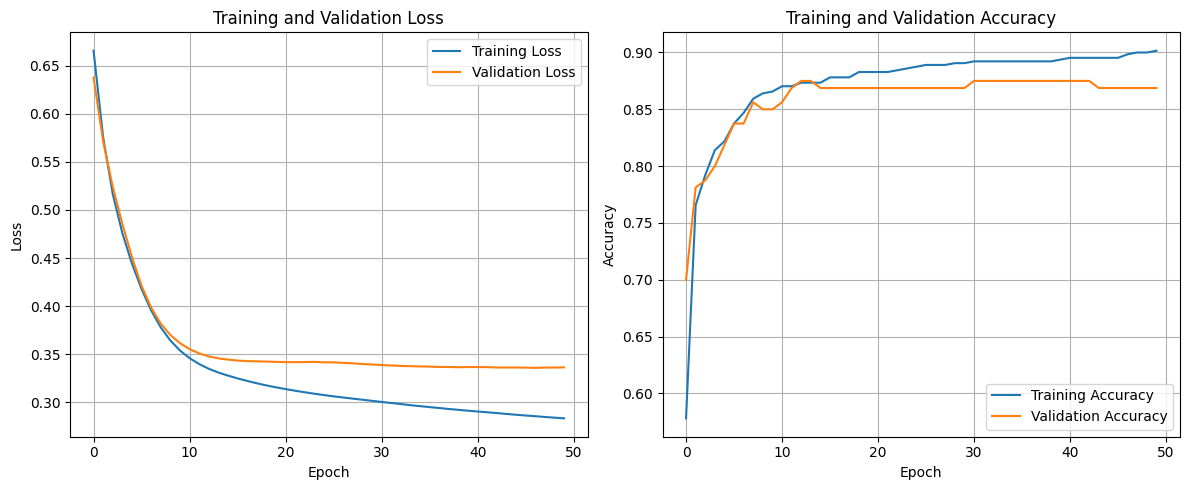

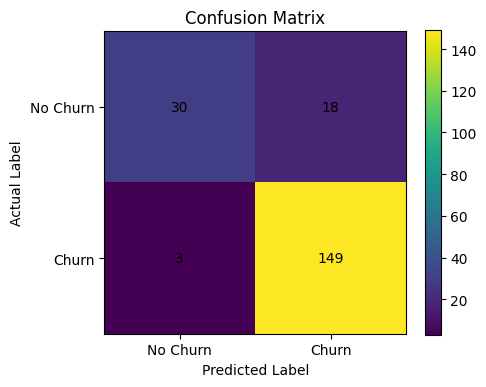

Hidden layer width 8: Accuracy = 0.8250


Hidden layer width 16: Accuracy = 0.8750


In [ ]:
# EXPERIMENT 9: MULTILAYER PERCEPTRON (MLP) FOR CUSTOMER CHURN PREDICTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

# 1. CREATE A SAMPLE TELECOM CUSTOMER DATASET
n = 1000

df = pd.DataFrame({
    'tenure': np.random.randint(1, 72, n),
    'monthly_charges': np.random.uniform(20, 120, n),
    'data_usage': np.random.uniform(1, 100, n),
    'complaints': np.random.randint(0, 6, n),
    'contract': np.random.choice(['Month-to-month', 'One year', 'Two year'], n)
})

# Generate churn labels
df['Churn'] = (
    (df['tenure'] < 15) |
    (df['monthly_charges'] > 90) |
    (df['complaints'] >= 3) |
    (df['contract'] == 'Month-to-month')
).astype(int)

# Add small random noise
noise = np.random.choice(n, 80, replace=False)
df.loc[noise, 'Churn'] = 1 - df.loc[noise, 'Churn']

print("Sample Dataset:")
print(df.head())

# 2. PREPROCESS THE DATA
X = pd.get_dummies(df.drop('Churn', axis=1), columns=['contract'])
y = df['Churn']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale numerical features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Validation split during training
# 3. BUILD AND TRAIN MLP MODEL

def build_model(width):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(width, activation='relu'),
        tf.keras.layers.Dense(width, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_model(16)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# 4. EVALUATE MODEL
y_prob = model.predict(X_test, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).flatten()

print("\nMODEL EVALUATION")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# PLOT TRAINING AND VALIDATION CURVES
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# PLOT CONFUSION MATRIX
plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation='nearest')
plt.title('Confusion Matrix')
plt.colorbar()
plt.xticks([0, 1], ['No Churn', 'Churn'])
plt.yticks([0, 1], ['No Churn', 'Churn'])
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.tight_layout()
plt.show()

# 5. VARY HIDDEN-LAYER WIDTH
widths = [8, 16, 32]
width_accuracies = []

for w in widths:
    temp_model = build_model(w)

    temp_model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    pred = (temp_model.predict(X_test, verbose=0) >= 0.5).astype(int).flatten()
    acc = accuracy_score(y_test, pred)
    width_accuracies.append(acc)

    print(f"Hidden layer width {w}: Accuracy = {acc:.4f}")

# PLOT WIDTH COMPARISON
plt.figure(figsize=(7, 5))
plt.plot(widths, width_accuracies, marker='o')
plt.title('Effect of Hidden Layer Width')
plt.xlabel('Hidden Layer Width')
plt.ylabel('Test Accuracy')
plt.xticks(widths)
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nExperiment 9 Completed Successfully!")